# 🗺️ Integración de Fuente Especializada Geoespacial (DENUE INEGI + OpenStreetMap + Marco Geoestadístico) y Linaje de Datos (Bronce $\rightarrow$ Plata $\rightarrow$ Oro)

**Proyecto Integrador — Entrega E2 (Unidad 4 — Ponderación: 20%)**  
**Observatorio Analítico del Mercado Inmobiliario y Renta Habitacional en la ZMVM**  
**Integrantes del Equipo:**
- Juan Antonio Ortiz Hinojosa
- Diego Alberto Virgen Cuéllar

---

## 🎯 Alcance del Notebook (`docs/E2/geoespacial_linaje.ipynb`)
Este cuaderno ejecutable documenta y verifica los tres pilares técnicos de la **Entrega E2**:
1. **Fuente Especializada Geoespacial (`GeoPandas` + `Shapely` + `Folium`):**
   - Integración de los polígonos de AGEB/Colonias del **Marco Geoestadístico Nacional (INEGI)**, densidad de unidades económicas de servicios y comercio del **DENUE (INEGI)** y nodos de transporte masivo (Metro, Metrobús, Suburbano) e infraestructura verde de **OpenStreetMap (OSM)**.
   - Reproyección métrica oficial a **UTM Zona 14N (`EPSG:32614`)** para calcular distancias euclidianas exactas en metros al transporte masivo (`dist_transporte_masivo_m`), unidades económicas en buffers de 500 metros (`denue_unidades_buffer_500m`) y el **Índice Compuesto de Accesibilidad y Equipamiento Urbano (`0-100`)**.
2. **Visualización Cartográfica Dual:**
   - Mapa coroplético de alta resolución (`docs/E2/mapa_coropletico_precio_equipamiento_zmvm.png`) y mapa interactivo HTML (`docs/E2/mapa_interactivo_zmvm.html`).
3. **Linaje y Trazabilidad Completa de Datos (100% Auditable):**
   - Verificación programática de que **cada uno de los 92 registros agregados en las 4 tablas de la Capa Oro** (`oro_e1`, `oro_e2`, `oro_e3` y `oro_geoespacial`) posee trazabilidad exacta hacia los registros primarios (`PROP-*`), archivos crudos en Capa Bronce, hash criptográfico SHA-256 del lote origen y timestamps UTC de ingesta.

In [1]:
import sys
from pathlib import Path
import json
import pandas as pd
import geopandas as gpd

PROJECT_ROOT = Path.cwd().resolve()
if (PROJECT_ROOT / "src").exists():
    ROOT_DIR = PROJECT_ROOT
else:
    ROOT_DIR = PROJECT_ROOT.parent.parent
sys.path.insert(0, str(ROOT_DIR))

from src.pipeline_e2 import (
    extract_geospatial_bronze_source,
    enrich_silver_with_geopandas_and_lineage,
    update_gold_layer_with_full_lineage,
    generate_cartographic_visualizations,
)

pd.set_option("display.max_columns", 25)
pd.set_option("display.width", 130)
print("Entorno GeoPandas cargado correctamente. Versión GeoPandas:", gpd.__version__)

Entorno GeoPandas cargado correctamente. Versión GeoPandas: 1.2.0


## 1. Captura Ética en Capa Bronce de la Fuente Geoespacial (DENUE INEGI + MGN + OpenStreetMap)
Se cargan los GeoDataFrames en `EPSG:4326` de las 16 colonias representativas de las 4 sub-zonas de estudio en la ZMVM y las 14 estaciones de transporte masivo cercanas, junto con la auditoría programática de `robots.txt`.

In [2]:
gdf_colonias, gdf_estaciones, geo_meta = extract_geospatial_bronze_source()
print("=== Metadatos y Auditoría Ética de la Fuente Geoespacial (Capa Bronce) ===")
print(json.dumps(geo_meta, indent=2, ensure_ascii=False))
display(gdf_colonias.drop(columns=["geometry"]).head(8))

=== Metadatos y Auditoría Ética de la Fuente Geoespacial (Capa Bronce) ===
{
  "fuente_especializada": "Geoespacial: DENUE (INEGI) + Marco Geoestadístico Nacional + OpenStreetMap",
  "fecha_ingesta_bronce_utc": "2026-11-21T18:52:17.580212+00:00",
  "crs_origen": "EPSG:4326 (WGS 84 Geográfico)",
  "crs_proyeccion_metrica": "EPSG:32614 (WGS 84 / UTM zone 14N en metros)",
  "total_poligonos_colonias_ageb": 16,
  "total_nodos_transporte_osm": 14,
  "robots_audit_inegi_denue": {
    "robots_url": "https://www.inegi.org.mx/robots.txt",
    "target_path": "/app/api/denue/v1/",
    "checked_at_utc": "2026-11-21T18:52:17.580305+00:00",
    "allowed": true,
    "crawl_delay_seconds": 2.0,
    "notes": "Verificación ética exitosa"
  },
  "robots_audit_osm_overpass": {
    "robots_url": "https://overpass-api.de/robots.txt",
    "target_path": "/api/interpreter",
    "checked_at_utc": "2026-11-21T18:52:17.894144+00:00",
    "allowed": false,
    "crawl_delay_seconds": 2.0,
    "notes": "Verificació

,colonia,subzona_id,cve_ent,cve_mun,cve_ageb_ref,lat_centroide,lon_centroide,denue_unidades_economicas_totales,denue_salud_educacion_scian61_62,osm_parques_areas_verdes,fuente_geoespacial,licencia_datos,fecha_ingesta_bronce_utc
0,Polanco,SZ1_PRIME_PONIENTE,09,016,090160001034A,19.4335,-99.1945,420,38,6,INEGI_DENUE_MGN + OPENSTREETMAP_OVERPASS,Libre Uso Datos Abiertos INEGI + ODbL 1.0 (Ope...,2026-11-21T18:52:17.580212+00:00
1,Anzures,SZ1_PRIME_PONIENTE,09,016,090160001048A,19.4330,-99.1765,295,24,3,INEGI_DENUE_MGN + OPENSTREETMAP_OVERPASS,Libre Uso Datos Abiertos INEGI + ODbL 1.0 (Ope...,2026-11-21T18:52:17.580212+00:00
2,Granada,SZ1_PRIME_PONIENTE,09,016,090160001021A,19.4425,-99.2015,340,29,4,INEGI_DENUE_MGN + OPENSTREETMAP_OVERPASS,Libre Uso Datos Abiertos INEGI + ODbL 1.0 (Ope...,2026-11-21T18:52:17.580212+00:00
3,Lomas de Chapultepec,SZ1_PRIME_PONIENTE,09,016,090160001062A,19.4235,-99.2160,245,22,7,INEGI_DENUE_MGN + OPENSTREETMAP_OVERPASS,Libre Uso Datos Abiertos INEGI + ODbL 1.0 (Ope...,2026-11-21T18:52:17.580212+00:00
4,Roma Norte,SZ2_CENTRAL_CORREDOR,09,015,090150001088A,19.4195,-99.1625,510,46,8,INEGI_DENUE_MGN + OPENSTREETMAP_OVERPASS,Libre Uso Datos Abiertos INEGI + ODbL 1.0 (Ope...,2026-11-21T18:52:17.580212+00:00
5,Hipódromo Condesa,SZ2_CENTRAL_CORREDOR,09,015,090150001095A,19.4115,-99.1735,465,34,9,INEGI_DENUE_MGN + OPENSTREETMAP_OVERPASS,Libre Uso Datos Abiertos INEGI + ODbL 1.0 (Ope...,2026-11-21T18:52:17.580212+00:00
6,Juárez,SZ2_CENTRAL_CORREDOR,09,015,090150001054A,19.4270,-99.1605,490,39,5,INEGI_DENUE_MGN + OPENSTREETMAP_OVERPASS,Libre Uso Datos Abiertos INEGI + ODbL 1.0 (Ope...,2026-11-21T18:52:17.580212+00:00
7,Cuauhtémoc,SZ2_CENTRAL_CORREDOR,09,015,090150001041A,19.4335,-99.1665,380,31,4,INEGI_DENUE_MGN + OPENSTREETMAP_OVERPASS,Libre Uso Datos Abiertos INEGI + ODbL 1.0 (Ope...,2026-11-21T18:52:17.580212+00:00


## 2. Procesamiento Espacial con `GeoPandas` (`EPSG:32614` UTM 14N) y Enriquecimiento de Capa Plata
Reproyectamos las geometrías de propiedades y estaciones de transporte al sistema métrico **WGS 84 / UTM zone 14N (`EPSG:32614`)** para medir distancias reales en metros y calcular el **Índice de Accesibilidad y Equipamiento Urbano (`0-100`)**, preservando privacidad por diseño (*k-anonimato espacial a nivel polígono de colonia/AGEB*).

In [3]:
gdf_silver_geo, spatial_summary = enrich_silver_with_geopandas_and_lineage(
    gdf_colonias, gdf_estaciones, geo_meta
)
print("=== Resumen del Enriquecimiento Espacial en Capa Plata ===")
print(json.dumps(spatial_summary, indent=2, ensure_ascii=False))

display(
    gdf_silver_geo[[
        "id_propiedad", "periodo_mensual", "colonia", "cve_ageb_inegi",
        "precio_m2_winsor_mxn", "dist_transporte_masivo_m", "estacion_transporte_cercana_osm",
        "denue_unidades_buffer_500m", "indice_accesibilidad_urbana_0_100",
        "linaje_fecha_captura_bronce_utc", "linaje_hash_registro_bronce"
    ]].head(8)
)

=== Resumen del Enriquecimiento Espacial en Capa Plata ===
{
  "total_inmuebles_georreferenciados": 1291,
  "distancia_media_transporte_m": 761.2,
  "distancia_mediana_transporte_m": 628.6,
  "denue_unidades_promedio_buffer_500m": 361.8,
  "indice_accesibilidad_promedio_0_100": 69.02,
  "correlacion_accesibilidad_vs_precio_m2": 0.0012,
  "archivo_plata_geolocalizado": "data\\silver\\inmobiliario\\rentas_zmvm_plata_geolocalizado_e2.csv"
}


,id_propiedad,periodo_mensual,colonia,cve_ageb_inegi,precio_m2_winsor_mxn,dist_transporte_masivo_m,estacion_transporte_cercana_osm,denue_unidades_buffer_500m,indice_accesibilidad_urbana_0_100,linaje_fecha_captura_bronce_utc,linaje_hash_registro_bronce
0,PROP-ACC81F8D42,2023-11,Polanco,090160001034A,436.58,590.4,Metro Polanco (Línea 7),405,75.53,2023-11-15T06:00:00Z,SHA256:6f7522509deb1207
1,PROP-4E2A0FC1CC,2023-11,Anzures,090160001048A,466.72,893.8,Metrobús Reforma / Gandhi,260,54.16,2023-11-15T06:00:00Z,SHA256:938353657e94dddf
2,PROP-898B72BF4C,2023-11,Granada,090160001021A,441.65,1227.6,Metro San Joaquín (Línea 7),313,53.65,2023-11-15T06:00:00Z,SHA256:ffddce0730355470
3,PROP-A7FA0E3263,2023-11,Polanco,090160001034A,406.18,413.5,Metro Polanco (Línea 7),404,78.63,2023-11-15T06:00:00Z,SHA256:022d0239b1696e47
4,PROP-39E1C13A7F,2023-11,Anzures,090160001048A,408.63,1017.6,Metrobús Reforma / Gandhi,325,56.93,2023-11-15T06:00:00Z,SHA256:20de0ce936a02abe
5,PROP-499C016032,2023-11,Granada,090160001021A,626.96,1186.2,Metro San Joaquín (Línea 7),307,53.93,2023-11-15T06:00:00Z,SHA256:c33818c5a6a97b95
6,PROP-D17B7B19BA,2023-11,Polanco,090160001034A,340.61,435.7,Metro Polanco (Línea 7),461,82.62,2023-11-15T06:00:00Z,SHA256:462937a8a9cae653
7,PROP-7CE310881F,2023-11,Anzures,090160001048A,345.02,1026.0,Metrobús Reforma / Gandhi,305,55.24,2023-11-15T06:00:00Z,SHA256:8560cc9081cd8f4a


## 3. Linaje y Trazabilidad Completa desde Capa Oro hasta Capa Bronce
Verificamos que cada registro de las **4 tablas de la Capa Oro** (`oro_e1_pronostico_mensual_trimestral.csv`, `oro_e2_simulacion_whatif_24m.csv`, `oro_e3_comparacion_multivariada_yield.csv` y `oro_geoespacial_colonias_denue_osm.csv`) esté vinculado en el catálogo maestro `data/gold/inmobiliario/catalogo_linaje_oro_a_bronce.csv` con sus IDs de origen en Bronce, archivos fuente, hash SHA-256 y fechas de ingesta.

In [4]:
lineage_summary = update_gold_layer_with_full_lineage(gdf_silver_geo)
print("=== Auditoría de Trazabilidad y Linaje (Oro -> Bronce) ===")
print(json.dumps(lineage_summary, indent=2, ensure_ascii=False))

df_gold_geo = pd.read_csv(ROOT_DIR / "data/gold/inmobiliario/oro_geoespacial_colonias_denue_osm.csv")
print("\n--- Cubo Oro Geoespacial por Colonia (DENUE + OSM + Rentas + Linaje) ---")
display(df_gold_geo[[
    "colonia", "subzona_id", "cve_ageb_inegi", "precio_m2_promedio_mxn",
    "yield_bruto_promedio_pct", "dist_transporte_masivo_m", "denue_unidades_buffer_500m",
    "indice_accesibilidad_urbana_0_100", "linaje_n_registros_bronce",
    "linaje_id_bronce_primero", "linaje_fecha_captura_bronce_min_utc", "linaje_hash_lote_bronce"
]])

df_catalogo_linaje = pd.read_csv(ROOT_DIR / "data/gold/inmobiliario/catalogo_linaje_oro_a_bronce.csv")
print("\n--- Muestra del Catálogo Maestro de Linaje (92 registros de Capa Oro auditados) ---")
display(df_catalogo_linaje.head(10))

=== Auditoría de Trazabilidad y Linaje (Oro -> Bronce) ===
{
  "total_registros_oro_auditados": 92,
  "registros_oro_con_linaje_completo_pct": 100.0,
  "registros_oro_huerfanos": 0,
  "desglose_tablas_oro": {
    "oro_e1_pronostico_mensual_trimestral": 36,
    "oro_e2_simulacion_whatif_24m": 28,
    "oro_e3_comparacion_multivariada_yield": 12,
    "oro_geoespacial_colonias_denue_osm": 16
  },
  "catalogo_linaje_csv": "data\\gold\\inmobiliario\\catalogo_linaje_oro_a_bronce.csv",
  "catalogo_linaje_json": "data\\gold\\inmobiliario\\catalogo_linaje_oro_a_bronce.json"
}

--- Cubo Oro Geoespacial por Colonia (DENUE + OSM + Rentas + Linaje) ---


,colonia,subzona_id,cve_ageb_inegi,precio_m2_promedio_mxn,yield_bruto_promedio_pct,dist_transporte_masivo_m,denue_unidades_buffer_500m,indice_accesibilidad_urbana_0_100,linaje_n_registros_bronce,linaje_id_bronce_primero,linaje_fecha_captura_bronce_min_utc,linaje_hash_lote_bronce
0,Anzures,SZ1_PRIME_PONIENTE,090160001048A,435.65,5.42,879.87,295.84,57.17,81,PROP-014505F471,2023-11-15T06:00:00Z,SHA256:414243a245c4c553
1,Granada,SZ1_PRIME_PONIENTE,090160001021A,440.83,5.42,1089.38,338.42,58.09,81,PROP-02DFE75E00,2023-11-15T06:00:00Z,SHA256:1ea501a3692ae617
2,Lomas de Chapultepec,SZ1_PRIME_PONIENTE,090160001062A,436.27,5.49,2832.25,244.12,48.45,80,PROP-09466D9962,2023-12-15T06:00:00Z,SHA256:065e4327609548a2
3,Polanco,SZ1_PRIME_PONIENTE,090160001034A,438.84,5.44,369.94,417.49,80.46,81,PROP-0B5170775D,2023-11-15T06:00:00Z,SHA256:932a5a34051a321d
4,Cuauhtémoc,SZ2_CENTRAL_CORREDOR,090150001041A,403.35,6.21,1042.11,379.17,62.08,81,PROP-0616F41C1F,2023-12-15T06:00:00Z,SHA256:eb36bdd9ca832b65
5,Hipódromo Condesa,SZ2_CENTRAL_CORREDOR,090150001095A,400.69,6.16,724.94,465.67,82.77,79,PROP-0053FC8331,2023-11-15T06:00:00Z,SHA256:cd548457a42a2939
6,Juárez,SZ2_CENTRAL_CORREDOR,090150001054A,403.49,6.32,425.32,493.80,83.34,81,PROP-049A9F6DB5,2023-11-15T06:00:00Z,SHA256:0e5d1f93f0a81ad2
7,Roma Norte,SZ2_CENTRAL_CORREDOR,090150001088A,403.32,6.27,470.45,508.80,88.25,81,PROP-05758C6FE8,2023-11-15T06:00:00Z,SHA256:84a0e1f47559ad0a
8,Del Valle Centro,SZ3_CONSOLIDADA_SUR,090140001032A,301.18,6.59,896.82,393.62,69.14,81,PROP-027CE732CF,2023-11-15T06:00:00Z,SHA256:59e0c972972ad69f
9,Narvarte Poniente,SZ3_CONSOLIDADA_SUR,090140001018A,299.31,6.65,1015.55,361.40,61.19,80,PROP-00E632117E,2023-11-15T06:00:00Z,SHA256:c551a7a350acf3cb



--- Muestra del Catálogo Maestro de Linaje (92 registros de Capa Oro auditados) ---


,id_linaje_oro,tabla_capa_oro,clave_registro_oro,n_registros_bronce_agregados,id_bronce_inicial,id_bronce_final,muestra_ids_bronce,archivos_bronce_origen,fecha_captura_bronce_min_utc,fecha_captura_bronce_max_utc,fecha_ingesta_geoespacial_utc,hash_lote_bronce,timestamp_promocion_oro_utc
0,LIN-ORO-ORO_E1-001,data/gold/inmobiliario/oro_e1_pronostico_mensu...,periodo_mensual=2023-11,36,PROP-00B2AED82D,PROP-FC035FD68A,PROP-00B2AED82D;PROP-07AA9798FA;PROP-169149B36...,rentas_zmvm_historico_36m.json+macro_banxico_i...,2023-11-15T06:00:00Z,2023-11-15T06:00:00Z,2026-11-21T18:52:17.580212+00:00,SHA256:0261220668a27953,2026-11-21T18:52:19.636626+00:00
1,LIN-ORO-ORO_E1-002,data/gold/inmobiliario/oro_e1_pronostico_mensu...,periodo_mensual=2023-12,36,PROP-062E93AA54,PROP-E9A75B209B,PROP-062E93AA54;PROP-14CF8F26E0;PROP-1A1FCDC8E...,rentas_zmvm_historico_36m.json+macro_banxico_i...,2023-12-15T06:00:00Z,2023-12-15T06:00:00Z,2026-11-21T18:52:17.580212+00:00,SHA256:67905948bb44bdb7,2026-11-21T18:52:19.636626+00:00
2,LIN-ORO-ORO_E1-003,data/gold/inmobiliario/oro_e1_pronostico_mensu...,periodo_mensual=2024-01,36,PROP-180E91D6E2,PROP-FE69DB4575,PROP-180E91D6E2;PROP-241C072E82;PROP-243FEFC7C...,rentas_zmvm_historico_36m.json+macro_banxico_i...,2024-01-15T06:00:00Z,2024-01-15T06:00:00Z,2026-11-21T18:52:17.580212+00:00,SHA256:58838d656837a8d5,2026-11-21T18:52:19.636626+00:00
3,LIN-ORO-ORO_E1-004,data/gold/inmobiliario/oro_e1_pronostico_mensu...,periodo_mensual=2024-02,36,PROP-025E69B591,PROP-F74406A34E,PROP-025E69B591;PROP-027CE732CF;PROP-08AE746E7...,rentas_zmvm_historico_36m.json+macro_banxico_i...,2024-02-15T06:00:00Z,2024-02-15T06:00:00Z,2026-11-21T18:52:17.580212+00:00,SHA256:f40a75db781549de,2026-11-21T18:52:19.636626+00:00
4,LIN-ORO-ORO_E1-005,data/gold/inmobiliario/oro_e1_pronostico_mensu...,periodo_mensual=2024-03,36,PROP-0053FC8331,PROP-F10C7723BA,PROP-0053FC8331;PROP-0153B04A18;PROP-049A9F6DB...,rentas_zmvm_historico_36m.json+macro_banxico_i...,2024-03-15T06:00:00Z,2024-03-15T06:00:00Z,2026-11-21T18:52:17.580212+00:00,SHA256:1cd43a9017d06857,2026-11-21T18:52:19.636626+00:00
5,LIN-ORO-ORO_E1-006,data/gold/inmobiliario/oro_e1_pronostico_mensu...,periodo_mensual=2024-04,35,PROP-070FD05D38,PROP-F9E18D2ABA,PROP-070FD05D38;PROP-0A6262E5C5;PROP-0E941C6A0...,rentas_zmvm_historico_36m.json+macro_banxico_i...,2024-04-15T06:00:00Z,2024-04-15T06:00:00Z,2026-11-21T18:52:17.580212+00:00,SHA256:a2c42e43f597aa04,2026-11-21T18:52:19.636626+00:00
6,LIN-ORO-ORO_E1-007,data/gold/inmobiliario/oro_e1_pronostico_mensu...,periodo_mensual=2024-05,36,PROP-0019DE65C5,PROP-F9F90F14B4,PROP-0019DE65C5;PROP-144B76F075;PROP-1B68D1F9D...,rentas_zmvm_historico_36m.json+macro_banxico_i...,2024-05-15T06:00:00Z,2024-05-15T06:00:00Z,2026-11-21T18:52:17.580212+00:00,SHA256:7c626496c9e56859,2026-11-21T18:52:19.636626+00:00
7,LIN-ORO-ORO_E1-008,data/gold/inmobiliario/oro_e1_pronostico_mensu...,periodo_mensual=2024-06,36,PROP-011F4EE111,PROP-EE0E4EB5C2,PROP-011F4EE111;PROP-05F127FD89;PROP-0B7137534...,rentas_zmvm_historico_36m.json+macro_banxico_i...,2024-06-15T06:00:00Z,2024-06-15T06:00:00Z,2026-11-21T18:52:17.580212+00:00,SHA256:a2525d9799093753,2026-11-21T18:52:19.636626+00:00
8,LIN-ORO-ORO_E1-009,data/gold/inmobiliario/oro_e1_pronostico_mensu...,periodo_mensual=2024-07,36,PROP-0917414F39,PROP-FF286C9508,PROP-0917414F39;PROP-1452E79171;PROP-1B2394237...,rentas_zmvm_historico_36m.json+macro_banxico_i...,2024-07-15T06:00:00Z,2024-07-15T06:00:00Z,2026-11-21T18:52:17.580212+00:00,SHA256:e18e03102f83dbd0,2026-11-21T18:52:19.636626+00:00
9,LIN-ORO-ORO_E1-010,data/gold/inmobiliario/oro_e1_pronostico_mensu...,periodo_mensual=2024-08,36,PROP-145B36F7C4,PROP-F934D48B69,PROP-145B36F7C4;PROP-162B5C4896;PROP-1C7DD6DDA...,rentas_zmvm_historico_36m.json+macro_banxico_i...,2024-08-15T06:00:00Z,2024-08-15T06:00:00Z,2026-11-21T18:52:17.580212+00:00,SHA256:00927099ef72cc9d,2026-11-21T18:52:19.636626+00:00


## 4. Visualización Cartográfica (`GeoPandas` + `Matplotlib` y `Folium`)
Generamos la lámina cartográfica dual de alta resolución (`docs/E2/mapa_coropletico_precio_equipamiento_zmvm.png`) y el mapa interactivo (`docs/E2/mapa_interactivo_zmvm.html`).

Artefactos cartográficos generados: {
  "mapa_coropletico_png": "docs\\E2\\mapa_coropletico_precio_equipamiento_zmvm.png",
  "mapa_interactivo_html": "docs\\E2\\mapa_interactivo_zmvm.html"
}


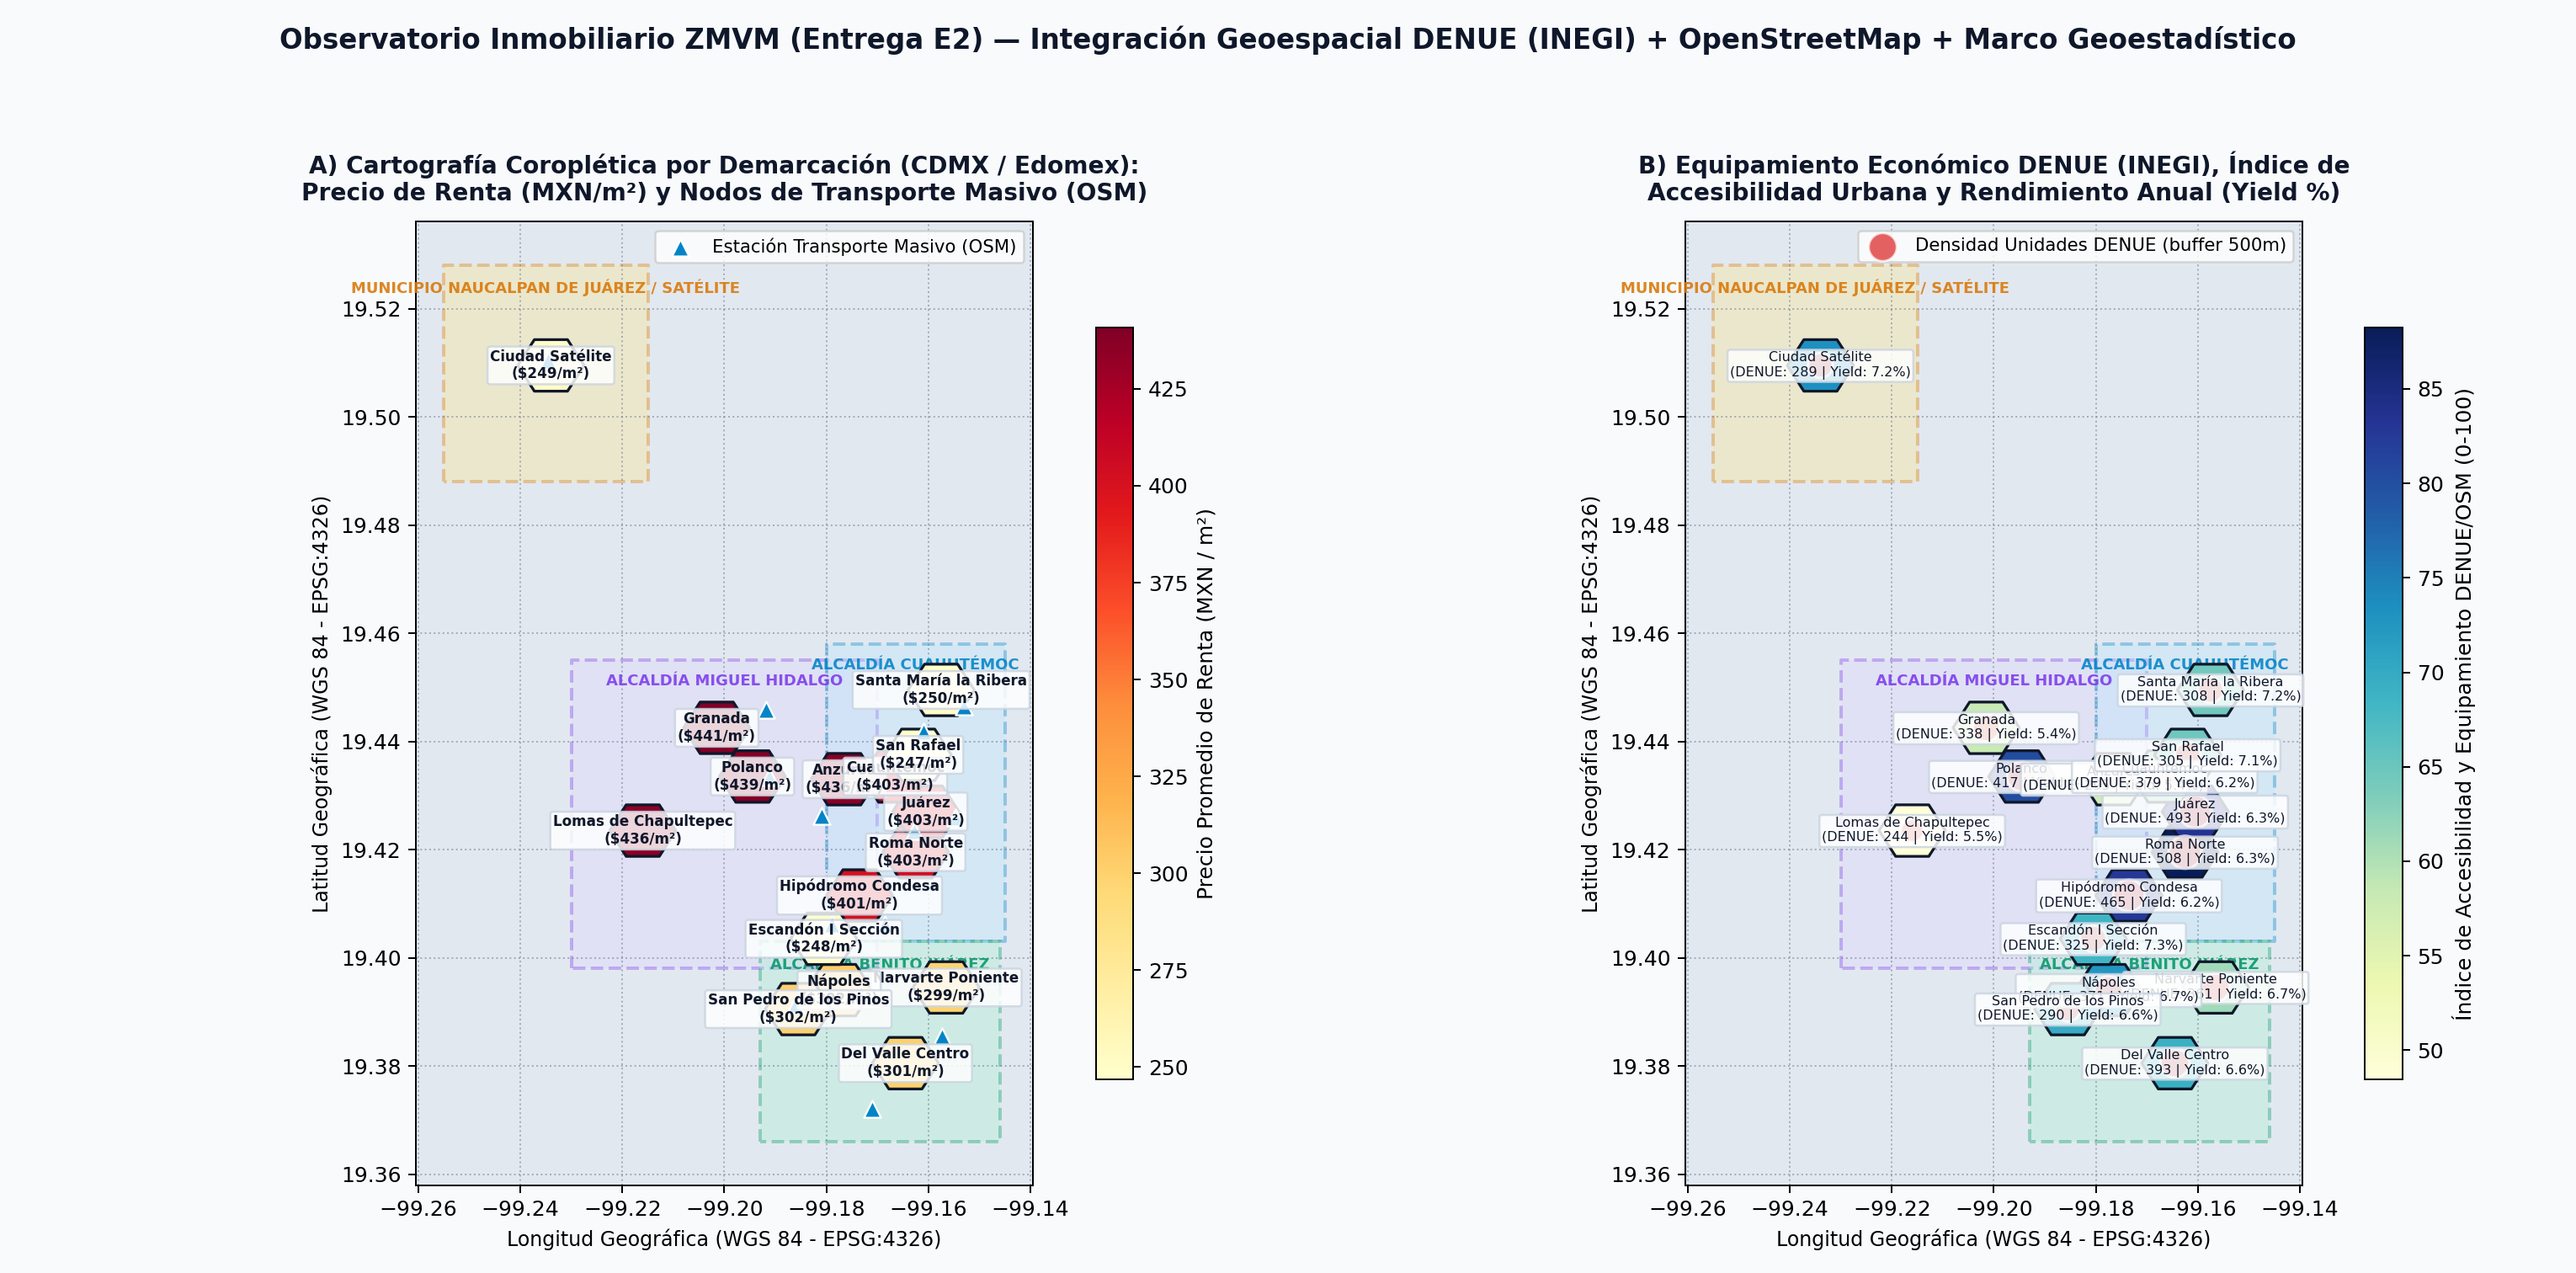

In [5]:
from IPython.display import Image, display as ipy_display

cart_outputs = generate_cartographic_visualizations(gdf_colonias, gdf_estaciones)
print("Artefactos cartográficos generados:", json.dumps(cart_outputs, indent=2))
ipy_display(Image(filename=str(ROOT_DIR / cart_outputs["mapa_coropletico_png"])))